In [36]:
import pandas as pd

client_train_data = pd.read_csv("data/client_train.csv", low_memory=False)
invoice_train_data = pd.read_csv("data/invoice_train.csv",  low_memory=False)

client_test_data = pd.read_csv("data/client_test.csv", low_memory=False)
invoice_test_data = pd.read_csv("data/invoice_test.csv",  low_memory=False)

In [37]:
client_train_data.head()

,disrict,client_id,client_catg,region,creation_date,target
0,60,train_Client_0,11,101,31/12/1994,0.0
1,69,train_Client_1,11,107,29/05/2002,0.0
2,62,train_Client_10,11,301,13/03/1986,0.0
3,69,train_Client_100,11,105,11/07/1996,0.0
4,62,train_Client_1000,11,303,14/10/2014,0.0


In [38]:
invoice_train_data.head(10)

,client_id,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,train_Client_0,2014-03-24,11,1335667,0,203,8,1,82,0,0,0,14302,14384,4,ELEC
1,train_Client_0,2013-03-29,11,1335667,0,203,6,1,1200,184,0,0,12294,13678,4,ELEC
2,train_Client_0,2015-03-23,11,1335667,0,203,8,1,123,0,0,0,14624,14747,4,ELEC
3,train_Client_0,2015-07-13,11,1335667,0,207,8,1,102,0,0,0,14747,14849,4,ELEC
4,train_Client_0,2016-11-17,11,1335667,0,207,9,1,572,0,0,0,15066,15638,12,ELEC
5,train_Client_0,2017-07-17,11,1335667,0,207,9,1,314,0,0,0,15638,15952,8,ELEC
6,train_Client_0,2018-12-07,11,1335667,0,207,9,1,541,0,0,0,15952,16493,12,ELEC
7,train_Client_0,2019-03-19,11,1335667,0,207,9,1,585,0,0,0,16493,17078,8,ELEC
8,train_Client_0,2011-07-22,11,1335667,0,203,9,1,1200,186,0,0,7770,9156,4,ELEC
9,train_Client_0,2011-11-22,11,1335667,0,203,6,1,1082,0,0,0,9156,10238,4,ELEC


In [39]:
# Change the date into a more readable format
client_train_data["creation_date"] = pd.to_datetime(client_train_data["creation_date"])
invoice_train_data["invoice_date"] = pd.to_datetime(invoice_train_data["invoice_date"])

d={"ELEC":0,"GAZ":1}
invoice_train_data['counter_type']=invoice_train_data['counter_type'].map(d)

client_train_data['client_catg'] = client_train_data['client_catg'].astype(int)
client_train_data['disrict'] = client_train_data['disrict'].astype(int)


C:\Users\tapio\AppData\Local\Temp\ipykernel_14128\3389100888.py:2: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  client_train_data["creation_date"] = pd.to_datetime(client_train_data["creation_date"])


In [40]:
# Aggregate the client data with the invoice data
merged_data = client_train_data.merge(invoice_train_data, on="client_id", how = "left", validate="1:m")
merged_data.head()


,disrict,client_id,client_catg,region,creation_date,target,invoice_date,tarif_type,counter_number,counter_statue,...,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,60,train_Client_0,11,101,1994-12-31,0.0,2014-03-24,11,1335667,0,...,8,1,82,0,0,0,14302,14384,4,0
1,60,train_Client_0,11,101,1994-12-31,0.0,2013-03-29,11,1335667,0,...,6,1,1200,184,0,0,12294,13678,4,0
2,60,train_Client_0,11,101,1994-12-31,0.0,2015-03-23,11,1335667,0,...,8,1,123,0,0,0,14624,14747,4,0
3,60,train_Client_0,11,101,1994-12-31,0.0,2015-07-13,11,1335667,0,...,8,1,102,0,0,0,14747,14849,4,0
4,60,train_Client_0,11,101,1994-12-31,0.0,2016-11-17,11,1335667,0,...,9,1,572,0,0,0,15066,15638,12,0


In [41]:
# Aggregate the client test data with the invoice data
merged_test_data = client_test_data.merge(invoice_test_data, on="client_id", how = "left", validate="1:m")
merged_test_data.head()

,disrict,client_id,client_catg,region,creation_date,invoice_date,tarif_type,counter_number,counter_statue,counter_code,reading_remarque,counter_coefficient,consommation_level_1,consommation_level_2,consommation_level_3,consommation_level_4,old_index,new_index,months_number,counter_type
0,62,test_Client_0,11,307,28/05/2002,2018-03-16,11,651208,0,203,8,1,755,0,0,0,19145,19900,8,ELEC
1,62,test_Client_0,11,307,28/05/2002,2014-03-21,11,651208,0,203,8,1,1067,0,0,0,13725,14792,8,ELEC
2,62,test_Client_0,11,307,28/05/2002,2014-07-17,11,651208,0,203,8,1,0,0,0,0,14792,14792,4,ELEC
3,62,test_Client_0,11,307,28/05/2002,2015-07-13,11,651208,0,203,9,1,410,0,0,0,16122,16532,4,ELEC
4,62,test_Client_0,11,307,28/05/2002,2016-07-19,11,651208,0,203,9,1,412,0,0,0,17471,17883,4,ELEC


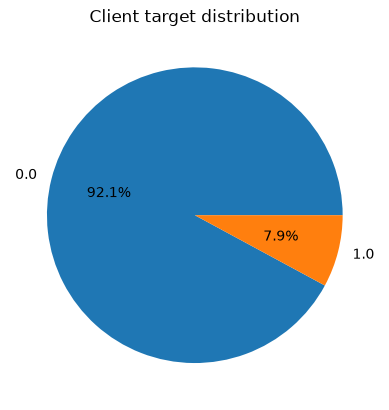

In [42]:
import matplotlib.pyplot as plt

target_counts = merged_data["target"].value_counts().sort_index()
plt.pie(
    target_counts,
    labels=target_counts.index,
    autopct="%1.1f%%"
)
plt.title("Client target distribution")
plt.show()

In [43]:
# Baseline Assumption:
# No client is fraudulent => 95% correct

<Axes: >

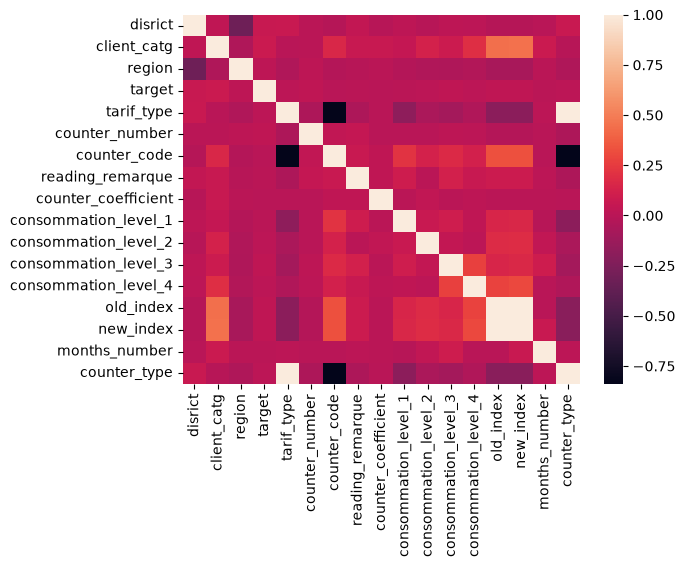

In [44]:
import seaborn as sns

cm = merged_data.select_dtypes(include="number").corr()
sns.heatmap(cm)

In [54]:
%pip install lightgbm
from lightgbm import LGBMClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

lgbm = LGBMClassifier()
pg = {
    "learning_rate": [0.01, 0.1, 0.2, 1],
    "n_estimators": [10, 100, 200],
    "subsample_for_bin": [1000, 10000, 20000],
}
gscv = GridSearchCV(
    estimator=lgbm,
    param_grid=pg,
    n_jobs=8,
    scoring="roc_auc"
)
y = merged_data["target"]

x = merged_data.drop(columns=["target"]).select_dtypes(include="number")
x = x.dropna(axis=1, how="all")

gscv.fit(x, y)

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.
[LightGBM] [Info] Number of positive: 353112, number of negative: 4123637
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.111024 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1756
[LightGBM] [Info] Number of data points in the train set: 4476749, number of used features: 16
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.078877 -> initscore=-2.457706
[LightGBM] [Info] Start training from score -2.457706


,estimator,LGBMClassifier()
,param_grid,"{'learning_rate': [0.01, 0.1, ...], 'n_estimators': [10, 100, ...], 'subsample_for_bin': [1000, 10000, ...]}"
,scoring,'roc_auc'
,n_jobs,8
,refit,True
,cv,None
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,boosting_type,'gbdt'


In [55]:
merged_test_data["counter_type"] = merged_test_data["counter_type"].map(d)

X_test = merged_test_data.reindex(columns=x.columns)
y_pred = gscv.predict(X_test)

<Axes: >

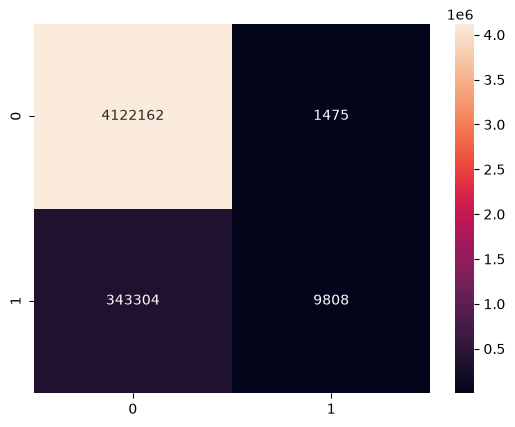

In [56]:
from sklearn.metrics import confusion_matrix

train_pred = gscv.predict(x)
cm = confusion_matrix(y, train_pred, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", xticklabels=[0, 1], yticklabels=[0, 1])